# CSE 4095 — Class 10: Comparing Models Fairly
Use AI to help design and implement the workflow, but you must control the comparison.

## Setup
Imports and a first look at the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [2]:
# keep_default_na=False stops pandas from reading the category "None" as missing.
# Only truly blank cells become NaN.
df = pd.read_csv("class1_student_habits.csv", keep_default_na=False, na_values=[""])
df.head()

,student_id,study_hours_per_week,sleep_hours_per_night,attendance_rate,practice_problems_per_week,prior_programming_experience,study_group,commute_minutes,quiz_average,exam_score
0,S001,1.3,7.7,71.8,8,Strong,No,0,67.0,64.6
1,S002,9.4,6.6,74.2,14,None,Yes,52,74.8,81.5
2,S003,11.2,6.1,70.3,15,Some,No,7,99.1,92.0
3,S004,10.8,7.6,77.1,16,Strong,No,12,86.4,100.0
4,S005,8.0,5.6,89.7,15,None,Yes,12,75.7,68.5


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   student_id                    250 non-null    str    
 1   study_hours_per_week          241 non-null    float64
 2   sleep_hours_per_night         238 non-null    float64
 3   attendance_rate               250 non-null    float64
 4   practice_problems_per_week    250 non-null    int64  
 5   prior_programming_experience  243 non-null    str    
 6   study_group                   250 non-null    str    
 7   commute_minutes               250 non-null    int64  
 8   quiz_average                  250 non-null    float64
 9   exam_score                    250 non-null    float64
dtypes: float64(5), int64(2), str(3)
memory usage: 19.7 KB


In [4]:
df.isna().sum()

student_id                       0
study_hours_per_week             9
sleep_hours_per_night           12
attendance_rate                  0
practice_problems_per_week       0
prior_programming_experience     7
study_group                      0
commute_minutes                  0
quiz_average                     0
exam_score                       0
dtype: int64

## Part 1 — Define the Classification Target
Create `high_exam_score`: "Yes" if `exam_score` >= 80, otherwise "No".

In [5]:
df["high_exam_score"] = np.where(df["exam_score"] >= 80, "Yes", "No")
df[["exam_score", "high_exam_score"]].head()

,exam_score,high_exam_score
0,64.6,No
1,81.5,Yes
2,92.0,Yes
3,100.0,Yes
4,68.5,No


In [6]:
class_counts = df["high_exam_score"].value_counts()
class_percents = df["high_exam_score"].value_counts(normalize=True) * 100

class_table = pd.DataFrame({"count": class_counts, "percent": class_percents.round(1)})
class_table

,count,percent
high_exam_score,,
No,151,60.4
Yes,99,39.6


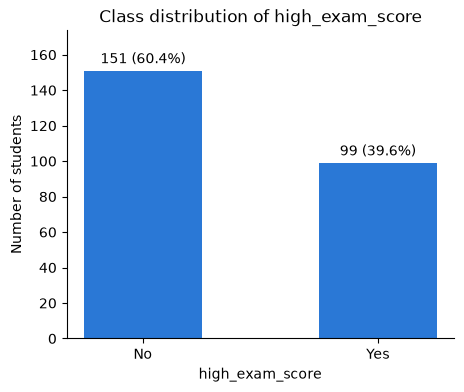

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(class_table.index, class_table["count"], width=0.5, color="#2a78d6")

# Label each bar with its count and percentage
labels = [f"{count} ({percent}%)" for count, percent in zip(class_table["count"], class_table["percent"])]
ax.bar_label(bars, labels=labels, padding=3)

ax.set_title("Class distribution of high_exam_score")
ax.set_xlabel("high_exam_score")
ax.set_ylabel("Number of students")
ax.set_ylim(0, class_table["count"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Part 1 Questions

**1. What are you trying to predict?**

**My answer:** We are trying to predict a high exam score. Whether a student gets a high score if exam_score >= 80. Prediction is made from student habits, before the exam happens. 

**2. Why is this a classification problem?**

**My answer:** This is a classification problem because the target has two discrete Yes and No labels. The model picks a category of these, not a number. 

**3. What percentage of students belong to each class?**

**My answer:** No = 60.4%, Yes = 39.6%

**4. Is the dataset approximately balanced?**

**My answer:** Not perfectly, it is a 60/40 split more or less. Mildly imbalanced

## Part 2 — Define X and y
Choose the feature columns, separate the features (X) from the target (y), and sort the features into numerical and categorical.

In [8]:
# Excluded on purpose: student_id, exam_score, and quiz_average are NOT features.
feature_columns = [
    "study_hours_per_week",
    "sleep_hours_per_night",
    "attendance_rate",
    "practice_problems_per_week",
    "prior_programming_experience",
    "study_group",
    "commute_minutes",
]

X = df[feature_columns]
y = df["high_exam_score"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (250, 7)
y shape: (250,)


In [9]:
X.dtypes

study_hours_per_week            float64
sleep_hours_per_night           float64
attendance_rate                 float64
practice_problems_per_week        int64
prior_programming_experience        str
study_group                         str
commute_minutes                   int64
dtype: object

In [10]:
# Number columns are numerical. Text columns are categorical.
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['study_hours_per_week', 'sleep_hours_per_night', 'attendance_rate', 'practice_problems_per_week', 'commute_minutes']
Categorical features: ['prior_programming_experience', 'study_group']


### Part 2 Questions

**1. Why would using exam_score be target leakage?**

**My answer:** Using exam_score would be considered leakage because this isn't information the model has at the time of a prediction. THis model's purpose is TO predict exam_score, based on other features of students. Using exam_score would cause perfect accuracy in cross_validation, but tells you nothing about how habits relate to exam scores to learn further. 

## Part 3 — Train/Test Split
Split the data 80/20. `stratify=y` keeps the same Yes/No mix in both sets.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (200, 7)
X_test:  (50, 7)
y_train: (200,)
y_test:  (50,)


In [12]:
# Class percentages should be nearly the same in all three columns
split_percents = pd.DataFrame({
    "full data": y.value_counts(normalize=True) * 100,
    "y_train": y_train.value_counts(normalize=True) * 100,
    "y_test": y_test.value_counts(normalize=True) * 100,
}).round(1)
split_percents

,full data,y_train,y_test
high_exam_score,,,
No,60.4,60.5,60.0
Yes,39.6,39.5,40.0


> ⚠️ **The test set is now locked away until Part 15.**
>
> `X_test` and `y_test` are not used for any model comparison, tuning, or experiment before Part 15. Every comparison from here on uses cross-validation on the training set only.

### Part 3 Questions

**1. Why are we holding the test set aside?**

**My answer:** If we were to use the test set, then it would cause more or less leakage. This test set stands in for future unseen students. The test set is for one final check at the end to compare our model. 

**2. What could happen if we repeatedly check test accuracy while modifying our model?**

**My answer:** If we did this, then the model will be tuned to those 50 specific students in the test set. The model becomes overly optimistic. 

## Part 4 — Preprocessing Pipeline
One `preprocessor` handles missing values, scaling, and one-hot encoding. `make_pipeline_for(model)` attaches it to any model so every model gets identical preprocessing.

In [13]:
# Numerical columns: fill blanks with the median, then scale to mean 0 and std 1
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Categorical columns: fill blanks with the most common value, then one-hot encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [14]:
def make_pipeline_for(model):
    """Return a Pipeline of a fresh copy of the preprocessor followed by the model."""
    # clone() gives each pipeline its own unfitted preprocessor, so pipelines never share fitted state
    return Pipeline([
        ("prep", clone(preprocessor)),
        ("model", model),
    ])

### Part 4 Questions

**1. Why should preprocessing be included inside the pipeline?**

**My answer:** Preprocessing shoudl be here because it's fit on training data only. The imputer's medians, the scaler's mean and std, and the encoder's categories are all learned values. Inside a pipeline, fit learns them from the training data only. 

**2. Why is this especially important when using cross-validation?**

**My answer:** This is useful because in each round of the CV, one fold plays the role of unseen data. If you preprocess the whole training set before CV, it leads to a small leak. 

**3. Which of the models in this assignment are sensitive to feature scaling?**

**My answer:** Logistic Regression is the most sensitive to this feature.

**4. Do Decision Trees and Random Forests generally require scaling?**

**My answer:** No, a tree splits one feature at a time with a threshold, so scaling changes that thresholds number, but not which students end up each side. This leads to the split and predictions being the same.

## Part 5 — Establish a Baseline
A majority-class baseline ignores every feature and always predicts the most common training label. Any real model has to beat it.

In [15]:
# One shared splitter: every model in this notebook is scored on these same 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [16]:
baseline = make_pipeline_for(DummyClassifier(strategy="most_frequent"))

baseline_scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="accuracy")

for fold, score in enumerate(baseline_scores, start=1):
    print(f"Fold {fold} accuracy: {score:.3f}")
print(f"Mean accuracy: {baseline_scores.mean():.3f}")
print(f"Std accuracy:  {baseline_scores.std():.3f}")

Fold 1 accuracy: 0.625
Fold 2 accuracy: 0.600
Fold 3 accuracy: 0.600
Fold 4 accuracy: 0.600
Fold 5 accuracy: 0.600
Mean accuracy: 0.605
Std accuracy:  0.010


### Part 5 Questions

**1. What does the baseline do?**

**My answer:** The baseline ignores every feature. During fit, it only counts which label is most common in the training forlds. It is a reference point. 

**2. What is its mean CV accuracy?**

**My answer:** .605 or 60.5%. 

**3. Why should our machine-learning models be compared with this baseline?**

**My answer:** Because it sets the bar, and is easy to compare if our models are better or worse than the baseline. 

## Part 6 — Understand Cross-Validation
The 200 training students are split into 5 folds. The model is trained 5 times. Each time, one fold is held out for validation and the other 4 are used for training.

```
Fold 1: VALIDATE | train    | train    | train    | train
Fold 2: train    | VALIDATE | train    | train    | train
Fold 3: train    | train    | VALIDATE | train    | train
Fold 4: train    | train    | train    | VALIDATE | train
Fold 5: train    | train    | train    | train    | VALIDATE
```

Every training student is used for validation exactly once. The test set is not part of any fold.

In [17]:
for fold, (train_rows, val_rows) in enumerate(cv.split(X_train, y_train), start=1):
    y_val = y_train.iloc[val_rows]
    percent_yes = (y_val == "Yes").mean() * 100
    print(f"Fold {fold}: {len(train_rows)} training rows, {len(val_rows)} validation rows, "
          f"{percent_yes:.1f}% Yes in validation")

Fold 1: 160 training rows, 40 validation rows, 37.5% Yes in validation
Fold 2: 160 training rows, 40 validation rows, 40.0% Yes in validation
Fold 3: 160 training rows, 40 validation rows, 40.0% Yes in validation
Fold 4: 160 training rows, 40 validation rows, 40.0% Yes in validation
Fold 5: 160 training rows, 40 validation rows, 40.0% Yes in validation


### Part 6 Questions

**1. What happens during 5-fold cross-validation?**

**My answer:**

**2. How many times is each model trained?**

**My answer:**

**3. Why is cross-validation more informative than a single training/validation split?**

**My answer:**

**4. Why do we still keep a separate final test set?**

**My answer:**

## Part 7 — Create the Three Models
Each model gets the same preprocessing through `make_pipeline_for`. They are only defined here, not evaluated.

In [18]:
# Logistic Regression: weighs each feature and turns the total into a probability of "Yes"
log_reg = make_pipeline_for(LogisticRegression(max_iter=1000, random_state=42))

# Decision Tree: asks up to 4 levels of yes/no questions about the features to reach a prediction
tree_d4 = make_pipeline_for(DecisionTreeClassifier(max_depth=4, random_state=42))

# Random Forest: 200 decision trees, each trained on a random sample of students, that vote on the answer
rf = make_pipeline_for(RandomForestClassifier(n_estimators=200, random_state=42))

## Part 8 — Compare the Models with Cross-Validation
All four models are scored on the same `cv` folds with the same three metrics. "Yes" is the positive class.

In [19]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label="Yes", zero_division=0),
    "recall": make_scorer(recall_score, pos_label="Yes", zero_division=0),
}


def evaluate_cv(name, pipeline):
    """Cross-validate a pipeline on the training set and return one row of the comparison table."""
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    # cross_validate names its keys "test_...", but these are the validation folds, NOT X_test
    return {
        "Model": name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Std. Accuracy": scores["test_accuracy"].std(),
        "Mean Precision": scores["test_precision"].mean(),
        "Mean Recall": scores["test_recall"].mean(),
    }

In [20]:
comparison = pd.DataFrame([
    evaluate_cv("Majority baseline", baseline),
    evaluate_cv("Logistic Regression", log_reg),
    evaluate_cv("Decision Tree (depth 4)", tree_d4),
    evaluate_cv("Random Forest", rf),
]).round(3)
comparison

,Model,Mean CV Accuracy,Std. Accuracy,Mean Precision,Mean Recall
0,Majority baseline,0.605,0.010,0.000,0.000
1,Logistic Regression,0.740,0.064,0.728,0.571
2,Decision Tree (depth 4),0.670,0.040,0.598,0.493
3,Random Forest,0.690,0.072,0.642,0.518


> **Use cautious language.** Each mean comes from only 5 folds of about 40 students, so one student changes a fold's accuracy by about 0.025. If the difference between two models is small compared with their Std. Accuracy, say they perform *similarly* or *slightly better*, not that one is clearly better.

### Part 8 Questions

**1. Which model has the highest mean CV accuracy?**

**My answer:**

**2. How large are the differences?**

**My answer:**

**3. Which model has the highest recall?**

**My answer:**

**4. Do all metrics identify the same model?**

**My answer:**

**5. How much does performance vary between folds?**

**My answer:**